# Do Richer Countries Keep More Children in School?

### An exploratory analysis of World Bank World Development Indicators (WDI)

**Mihail Deligrozev** · Data analysis with Python (pandas, matplotlib, SciPy)

*Originally completed as Assignment 1 (Data Collection and Wrangling) of EPA-1316 Introduction to Urban Data Science, TU Delft. This version is restructured as a standalone case study.*

---

## Summary

**Question.** Are children and adolescents more likely to be out of school in poorer countries, and does higher government spending per student help?

**Data.** The World Bank's World Development Indicators: 379,368 rows covering 264 countries/aggregates and 1,437 indicators, 1960 to 2019, in "long" format.

**What I did.** Loaded and profiled the raw file, selected five indicators, picked the best-covered recent year (2015), handled missing data, reshaped from long to wide format (one row per country), and ran a first exploratory check of the hypothesis.

**Result in one line.** Wealth is strongly associated with lower out-of-school rates; government spending per student shows no clear relationship once you look at the data (see the findings at the end).

**Data-quality catch.** The WDI file mixes real countries with 47 regional and income-group aggregates ("South Asia", "World", "Low income"...). Leaving them in would silently double count countries and distort any statistics, so I removed them before analysing.

| Step | Skills shown |
| --- | --- |
| Load and profile | pandas, large CSV handling, data-quality checks |
| Subset and choose a year | hypothesis framing, coverage trade-offs |
| Missing data | evidence-based decision, bias check |
| Reshape | long-to-wide pivot |
| Explore | rank correlation, scatter plots, interpretation and limitations |

## 1. Load and profile the data

The raw file `WDIData.csv` comes from the [World Bank data catalog](http://data.worldbank.org/data-catalog/world-development-indicators). Each row is one **country × indicator** combination, and each year from 1960 to 2019 is a column. The notebook expects this layout:

```text
├── world_bank_school_dropout_analysis.ipynb
└── data
    └── WDIData.csv
```

Paths are relative, so it runs on any machine.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 12)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
df = pd.read_csv("data/WDIData.csv")
df.shape

(379368, 65)

First and last five rows:

In [3]:
df.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,1966,1967,1968,1969,1970,1971,1972,1973,1974,1975,1976,1977,1978,1979,1980,1981,1982,1983,1984,1985,1986,1987,1988,1989,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,Unnamed: 64
0,Arab World,ARB,Access to clean fuels and technologies for cooking (% of population),EG.CFT.ACCS.ZS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Arab World,ARB,Access to electricity (% of population),EG.ELC.ACCS.ZS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Arab World,ARB,"Access to electricity, rural (% of rural population)",EG.ELC.ACCS.RU.ZS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Arab World,ARB,"Access to electricity, urban (% of urban population)",EG.ELC.ACCS.UR.ZS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Arab World,ARB,Account ownership at a financial institution or with a mobile-money-service provider (% of population ages 15+),FX.OWN.TOTL.ZS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,22.260538,NaN,NaN,30.27713,NaN,NaN,37.165211,NaN,NaN,NaN


In [4]:
df.tail()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,1966,1967,1968,1969,1970,1971,1972,1973,1974,1975,1976,1977,1978,1979,1980,1981,1982,1983,1984,1985,1986,1987,1988,1989,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,Unnamed: 64
379363,Zimbabwe,ZWE,Women who believe a husband is justified in beating his wife when she neglects the children (%),SG.VAW.NEGL.ZS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,31.2,NaN,NaN,NaN,NaN,NaN,NaN,30.2,NaN,NaN,NaN,NaN,21.4,NaN,NaN,NaN,21.4,NaN,NaN,NaN,NaN,NaN
379364,Zimbabwe,ZWE,Women who believe a husband is justified in beating his wife when she refuses sex with him (%),SG.VAW.REFU.ZS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,22.3,NaN,NaN,NaN,NaN,NaN,NaN,24.3,NaN,NaN,NaN,NaN,16.9,NaN,NaN,NaN,14.5,NaN,NaN,NaN,NaN,NaN
379365,Zimbabwe,ZWE,Women who were first married by age 15 (% of women ages 20-24),SP.M15.2024.FE.ZS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.7,NaN,NaN,NaN,NaN,NaN,6.4,NaN,NaN,NaN,NaN,4.6,NaN,NaN,NaN,NaN,NaN,NaN,4.6,NaN,NaN,NaN,NaN,3.9,NaN,NaN,NaN,3.7,NaN,NaN,NaN,NaN,NaN
379366,Zimbabwe,ZWE,Women who were first married by age 18 (% of women ages 20-24),SP.M18.2024.FE.ZS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,33.1,NaN,NaN,NaN,NaN,NaN,31.0,NaN,NaN,NaN,NaN,28.7,NaN,NaN,NaN,NaN,NaN,NaN,33.6,NaN,NaN,30.1,NaN,30.5,NaN,NaN,33.5,32.4,NaN,NaN,NaN,NaN,NaN
379367,Zimbabwe,ZWE,Women's share of population ages 15+ living with HIV (%),SH.DYN.AIDS.FE.ZS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,46.3,47.8,49.0,50.0,50.8,51.6,52.3,52.9,53.5,54.0,54.6,55.2,55.7,56.2,56.6,57.0,57.4,57.7,57.9,58.1,58.9,59.0,59.2,59.3,59.4,59.4,59.5,59.5,59.6,59.6,NaN


### What does the data look like?

The questions for this section: how many rows and columns, what are the columns called, how many countries and indicators, and anything else worth knowing.

In [5]:
# The file ends every line with a trailing comma, so pandas creates an empty last column. Drop it.
empty_cols = [c for c in df.columns if df[c].isna().all()]
print("Empty columns dropped:", empty_cols)
df = df.drop(columns=empty_cols)

year_cols = [c for c in df.columns if c.isdigit()]
id_cols = [c for c in df.columns if not c.isdigit()]

print(f"Rows (excluding header):   {len(df):,}")
print(f"Columns:                   {df.shape[1]}  ({len(id_cols)} identifier columns + {len(year_cols)} year columns)")
print(f"Identifier columns:        {id_cols}")
print(f"Year columns:              {year_cols[0]} to {year_cols[-1]}")
print(f"Unique countries/regions:  {df['Country Code'].nunique()}")
print(f"Unique indicators:         {df['Indicator Code'].nunique():,}")
print(f"Share of year cells that hold a value: {df[year_cols].notna().mean().mean():.1%}")

Empty columns dropped: ['Unnamed: 64']
Rows (excluding header):   379,368
Columns:                   64  (4 identifier columns + 60 year columns)
Identifier columns:        ['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code']
Year columns:              1960 to 2019
Unique countries/regions:  264
Unique indicators:         1,437
Share of year cells that hold a value: 33.1%


**Answers**

- **Rows:** 379,368, which is 264 countries/regions × 1,437 indicators (every combination exists, many are simply empty).
- **Columns:** 64 after dropping an empty artefact column: 4 identifiers and 60 years (1960 to 2019).
- **Unique countries/regions:** 264, **unique indicators:** 1,437.
- **Missingness:** only about a third of the year cells contain data, so choosing indicators and years carefully matters a lot.

### Coverage by year

Data is much sparser in the early decades, and the most recent years are still being back-filled by countries.

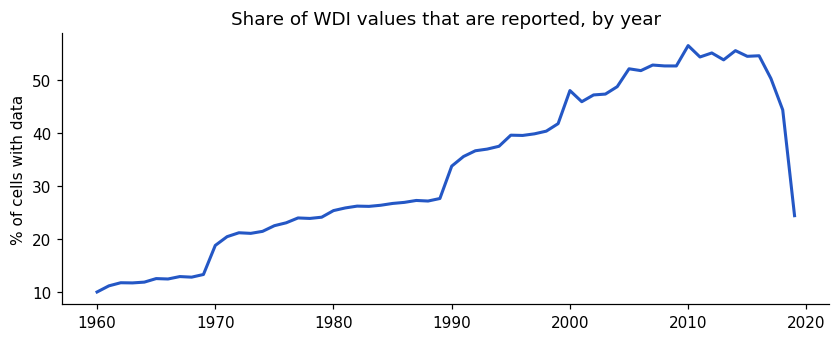

In [6]:
coverage = df[year_cols].notna().mean().mul(100)

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(pd.to_numeric(coverage.index), coverage.values, color="#2457c5", lw=2)
ax.set_ylabel("% of cells with data")
ax.set_title("Share of WDI values that are reported, by year")
plt.show()

### Countries versus aggregates

The 264 "countries" are not all countries. The first 47 entries are regional or income groupings published by the World Bank (Arab World, East Asia & Pacific, High income, World, and so on). They overlap with the real countries, so mixing the two would count the same people several times. I list their codes explicitly (codes are more stable than names) and keep only the 217 individual economies for analysis.

In [7]:
AGGREGATES = [
    "ARB","CSS","CEB","EAR","EAS","EAP","TEA","EMU","ECS","ECA","TEC","EUU","FCS","HPC",
    "HIC","IBD","IBT","IDB","IDX","IDA","LTE","LCN","LAC","TLA","LDC","LMY","LIC","LMC",
    "MEA","MNA","TMN","MIC","NAC","INX","OED","OSS","PSS","PST","PRE","SST","SAS","TSA",
    "SSF","SSA","TSS","UMC","WLD",
]
all_codes = df["Country Code"].unique()
print(f"Aggregates: {len(AGGREGATES)}  |  individual economies: {len(set(all_codes) - set(AGGREGATES))}")
print("Examples:", list(df[df["Country Code"].isin(AGGREGATES)]["Country Name"].unique()[:6]))

Aggregates: 47  |  individual economies: 217
Examples: ['Arab World', 'Caribbean small states', 'Central Europe and the Baltics', 'Early-demographic dividend', 'East Asia & Pacific', 'East Asia & Pacific (excluding high income)']


## 2. Subset the data

### Hypothesis

I want to understand **why children and adolescents drop out of school around the world**, and in particular whether national wealth and public spending explain it.

- **H1:** Countries with higher GDP per capita have lower out-of-school rates.
- **H2:** Countries that spend less per student have higher out-of-school rates.

Five indicators (the two outcomes, two spending controls, and wealth):

| Role | Variable | Code |
| --- | --- | --- |
| Outcome | Children out of school (% of primary school age) | `SE.PRM.UNER.ZS` |
| Outcome | Adolescents out of school (% of lower secondary school age) | `SE.SEC.UNER.LO.ZS` |
| Explanatory | Government expenditure per student, primary (% of GDP per capita) | `SE.XPD.PRIM.PC.ZS` |
| Explanatory | Government expenditure per student, secondary (% of GDP per capita) | `SE.XPD.SECO.PC.ZS` |
| Explanatory | GDP per capita (current US$) | `NY.GDP.PCAP.CD` |

In [8]:
VARIABLES = {
    "SE.PRM.UNER.ZS":    "Children out of School",
    "SE.SEC.UNER.LO.ZS": "Adolescents out of School",
    "SE.XPD.PRIM.PC.ZS": "Govt Primary Expenditure",
    "SE.XPD.SECO.PC.ZS": "Govt Secondary Expenditure",
    "NY.GDP.PCAP.CD":    "GDP Per Capita",
}

subset = df[df["Indicator Code"].isin(VARIABLES) & ~df["Country Code"].isin(AGGREGATES)]

print(f"Rows:                  {len(subset):,}  (217 economies x 5 indicators = {217*5:,})")
print(f"Columns:               {subset.shape[1]}")
print(f"Unique economies:      {subset['Country Code'].nunique()}")
print(f"Indicators:            {sorted(subset['Indicator Name'].unique())}")
subset[id_cols + ["2015"]].head()

Rows:                  1,085  (217 economies x 5 indicators = 1,085)
Columns:               64
Unique economies:      217
Indicators:            ['Adolescents out of school (% of lower secondary school age)', 'Children out of school (% of primary school age)', 'GDP per capita (current US$)', 'Government expenditure per student, primary (% of GDP per capita)', 'Government expenditure per student, secondary (% of GDP per capita)']


,Country Name,Country Code,Indicator Name,Indicator Code,2015
67588,Afghanistan,AFG,Adolescents out of school (% of lower secondary school age),SE.SEC.UNER.LO.ZS,NaN
67716,Afghanistan,AFG,Children out of school (% of primary school age),SE.PRM.UNER.ZS,NaN
68013,Afghanistan,AFG,GDP per capita (current US$),NY.GDP.PCAP.CD,578.466353
68053,Afghanistan,AFG,"Government expenditure per student, primary (% of GDP per capita)",SE.XPD.PRIM.PC.ZS,10.246880
68054,Afghanistan,AFG,"Government expenditure per student, secondary (% of GDP per capita)",SE.XPD.SECO.PC.ZS,10.292340


### Choosing one year

To keep this a cross-section (no time-series complexity), I need a single year in which as many countries as possible report **all five** indicators. The table counts, for each recent year, how many indicators each have and how many countries have all five at once.

In [9]:
rows = []
for year in map(str, range(2008, 2019)):
    wide = subset.pivot(index="Country Code", columns="Indicator Code", values=year)
    rows.append({"Year": year, **wide.notna().sum().rename(VARIABLES).to_dict(),
                 "Countries with all 5": len(wide.dropna())})
year_coverage = pd.DataFrame(rows).set_index("Year")
year_coverage

,GDP Per Capita,Children out of School,Adolescents out of School,Govt Primary Expenditure,Govt Secondary Expenditure,Countries with all 5
Year,,,,,,
2008,205,127,88,88,77,50
2009,205,127,98,92,79,53
2010,206,124,91,101,90,53
2011,207,130,97,104,95,59
2012,206,136,94,95,81,50
2013,206,126,100,101,94,60
2014,205,129,108,93,84,54
2015,204,130,110,89,83,55
2016,203,133,106,82,77,49


Spending data thins out sharply after 2016 (the 2017 and 2018 columns are far from complete). Coverage peaks around 2011 and 2013, but I chose **2015** because it is recent enough to describe the world just before the data thins out and it keeps 55 complete countries, close to the best years. Choosing a year is a trade-off between recency and sample size; 2013 or 2011 would be reasonable alternatives and could be used as a robustness check.

In [10]:
YEAR = "2015"

long_2015 = subset[["Country Code", "Indicator Code", YEAR]]
long_2015.head()

,Country Code,Indicator Code,2015
67588,AFG,SE.SEC.UNER.LO.ZS,NaN
67716,AFG,SE.PRM.UNER.ZS,NaN
68013,AFG,NY.GDP.PCAP.CD,578.466353
68053,AFG,SE.XPD.PRIM.PC.ZS,10.246880
68054,AFG,SE.XPD.SECO.PC.ZS,10.292340


## 3. Reshape from long to wide

Each row is currently one country-indicator pair. For analysis I want **one row per country** and **one column per indicator**, which is a pivot.

In [11]:
wide = long_2015.pivot(index="Country Code", columns="Indicator Code", values=YEAR)
wide = wide.rename(columns=VARIABLES)[list(VARIABLES.values())]   # readable names, fixed column order
wide.columns.name = None
print("Shape after pivot:", wide.shape)
wide.head()

Shape after pivot: (217, 5)


,Children out of School,Adolescents out of School,Govt Primary Expenditure,Govt Secondary Expenditure,GDP Per Capita
Country Code,,,,,
ABW,NaN,NaN,NaN,NaN,27980.880695
AFG,NaN,NaN,10.24688,10.29234,578.466353
AGO,NaN,NaN,NaN,NaN,4166.979684
ALB,2.20127,3.05841,29.84568,6.78368,3952.801215
AND,NaN,NaN,13.45657,14.38817,35762.523074


## 4. Manage missing data

### Why is data missing?

There are two reasons visible in this dataset:

1. **Reporting gaps.** Out-of-school rates and spending per student depend on national education statistics (enrolment registers and household surveys). Not every country reports every year.
2. **Variable-specific coverage.** Spending per *secondary* student is reported by fewer countries than primary spending, which is reported by fewer than the out-of-school rates. GDP per capita comes from national accounts, which almost every economy produces.

In [12]:
missing = pd.DataFrame({
    "Missing": wide.isna().sum(),
    "% missing": (wide.isna().mean() * 100).round(1),
})
missing

,Missing,% missing
Children out of School,87,40.1
Adolescents out of School,107,49.3
Govt Primary Expenditure,128,59.0
Govt Secondary Expenditure,134,61.8
GDP Per Capita,13,6.0


### Decision

| Column | Missing (of 217) | Decision | Reason |
| --- | --- | --- | --- |
| GDP Per Capita | 13 | Drop those countries | Needed for H1. The gaps are a mix of small territories (e.g. Bermuda, Gibraltar, New Caledonia) and countries with no published 2015 estimate (e.g. Eritrea, Somalia, Syria, Venezuela) |
| Children out of School | 87 | Drop those countries | This is an outcome; imputing the thing I am trying to explain would be circular |
| Adolescents out of School | 107 | Drop those countries | Same reasoning as above |
| Govt Primary Expenditure | 128 | Drop those countries | Mean or median imputation would invent values for a variable the hypothesis depends on, and more than half of it is missing |
| Govt Secondary Expenditure | 134 | Drop those countries | Same as above; this is the sparsest column |

I use **listwise deletion** (strategies 1 and 3 from the course text: drop cases, and choose a year with limited missingness). It is simple and transparent, but it shrinks the sample, so before accepting it I check **whether the dropped countries are systematically different** from the kept ones.

In [13]:
complete = wide.dropna()
dropped = wide.drop(complete.index)

print(f"Countries kept (all 5 indicators present): {len(complete)}")
print(f"Countries dropped:                         {len(dropped)}")
print()
print("Median GDP per capita (US$):")
print(f"  kept    {complete['GDP Per Capita'].median():>9,.0f}")
print(f"  dropped {dropped['GDP Per Capita'].median():>9,.0f}")

Countries kept (all 5 indicators present): 55
Countries dropped:                         162

Median GDP per capita (US$):
  kept       13,789
  dropped     4,178


**Important caveat:** the countries that report everything are noticeably **wealthier** (median GDP per capita roughly three times higher) than those that don't. The final sample therefore under-represents the poorest countries, which are exactly where out-of-school rates are highest. Any conclusion applies to "countries that report all five indicators", not to the whole world.

In [14]:
print("Missing values after cleaning:")
print(complete.isna().sum().to_string())
print()
complete.info()

Missing values after cleaning:
Children out of School        0
Adolescents out of School     0
Govt Primary Expenditure      0
Govt Secondary Expenditure    0
GDP Per Capita                0

<class 'pandas.DataFrame'>
Index: 55 entries, ALB to VUT
Data columns (total 5 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Children out of School      55 non-null     float64
 1   Adolescents out of School   55 non-null     float64
 2   Govt Primary Expenditure    55 non-null     float64
 3   Govt Secondary Expenditure  55 non-null     float64
 4   GDP Per Capita              55 non-null     float64
dtypes: float64(5)
memory usage: 2.6+ KB


## 5. Final tidy table

Columns already have readable names. The table is sorted by the **share of children out of school (highest first)**; ties are broken by country code, descending.

In [15]:
clean = complete.sort_values(["Children out of School"], ascending=False)
print("Shape:", clean.shape)
clean.head()

Shape: (55, 5)


,Children out of School,Adolescents out of School,Govt Primary Expenditure,Govt Secondary Expenditure,GDP Per Capita
Country Code,,,,,
MLI,39.29094,45.15668,13.43451,23.14329,751.478669
NER,37.50665,69.02974,22.53418,65.02605,483.339282
PAK,32.61325,38.65668,8.09756,16.02248,1356.667756
BFA,29.94701,41.97937,16.13029,17.26223,653.326980
ETH,14.37807,47.04813,7.87686,16.76439,640.541891


In [16]:
clean.tail()

,Children out of School,Adolescents out of School,Govt Primary Expenditure,Govt Secondary Expenditure,GDP Per Capita
Country Code,,,,,
LTU,0.08215,0.08875,18.59952,17.42974,14249.114967
GBR,0.06567,1.82057,24.97949,23.05669,44974.831877
ARG,0.05630,0.38344,15.64309,22.87436,13789.060425
IRL,0.04882,0.30251,11.83086,16.42230,61995.422779
SWE,0.00258,0.15907,21.33574,23.58743,51545.483610


In [17]:
clean.describe().round(2)

,Children out of School,Adolescents out of School,Govt Primary Expenditure,Govt Secondary Expenditure,GDP Per Capita
count,55.00,55.00,55.00,55.00,55.00
mean,5.06,7.94,18.93,21.73,22868.40
std,9.11,14.26,6.70,8.82,23060.27
min,0.00,0.05,7.88,5.07,483.34
25%,0.54,0.50,14.89,16.95,5854.80
50%,1.41,2.30,18.34,21.17,13789.06
75%,4.86,7.03,22.34,25.46,37627.09
max,39.29,69.03,43.65,65.03,101376.50


## 6. First look at the hypotheses

This goes beyond the wrangling brief: a first exploratory check of H1 and H2. I use **Spearman rank correlation** because the variables are heavily skewed (GDP per capita spans roughly 500 to 100,000 US$) and ranks are not distorted by outliers. GDP is drawn on a log scale for the same reason.

In [18]:
tests = [
    ("GDP Per Capita",             "Children out of School"),
    ("GDP Per Capita",             "Adolescents out of School"),
    ("Govt Primary Expenditure",   "Children out of School"),
    ("Govt Secondary Expenditure", "Adolescents out of School"),
]
results = []
for x, y in tests:
    rho, p = spearmanr(clean[x], clean[y])
    results.append({"Explanatory": x, "Outcome": y, "Spearman rho": round(rho, 2), "p-value": "< 0.001" if p < 0.001 else round(p, 3), "n": len(clean)})
pd.DataFrame(results)

,Explanatory,Outcome,Spearman rho,p-value,n
0,GDP Per Capita,Children out of School,-0.70,< 0.001,55
1,GDP Per Capita,Adolescents out of School,-0.70,< 0.001,55
2,Govt Primary Expenditure,Children out of School,-0.22,0.106,55
3,Govt Secondary Expenditure,Adolescents out of School,-0.03,0.849,55


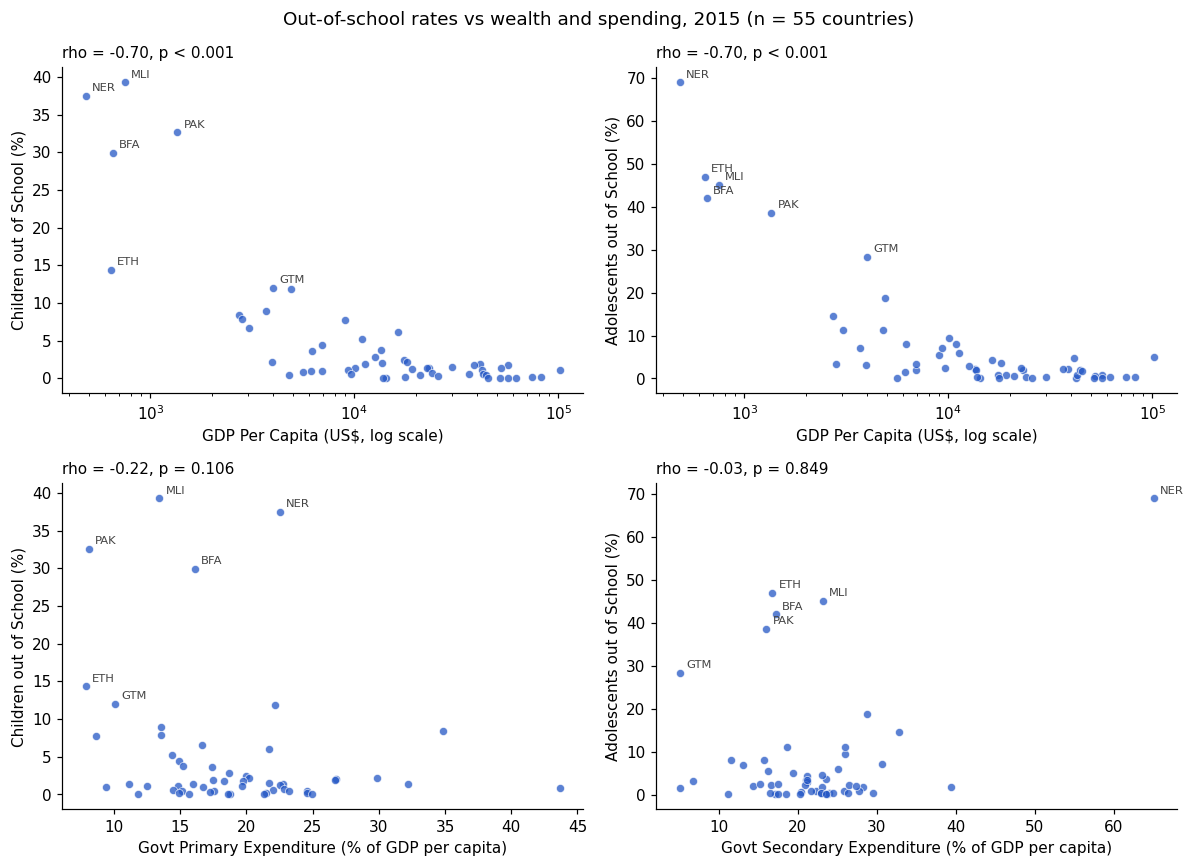

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
labels = ["MLI", "NER", "PAK", "BFA", "ETH", "GTM"]

for ax, (x, y) in zip(axes.ravel(), tests):
    rho, p = spearmanr(clean[x], clean[y])
    ax.scatter(clean[x], clean[y], s=28, alpha=.75, color="#2457c5", edgecolor="white", lw=.5)
    if x == "GDP Per Capita":
        ax.set_xscale("log")
    for code_, row in clean.loc[clean.index.intersection(labels)].iterrows():
        ax.annotate(code_, (row[x], row[y]), xytext=(4, 3), textcoords="offset points", fontsize=7.5, color="#444")
    ax.set_xlabel(x + (" (US$, log scale)" if x == "GDP Per Capita" else " (% of GDP per capita)"))
    ax.set_ylabel(y + " (%)")
    ax.set_title(f"rho = {rho:.2f}, " + ("p < 0.001" if p < 0.001 else f"p = {p:.3f}"), fontsize=10, loc="left")

fig.suptitle(f"Out-of-school rates vs wealth and spending, {YEAR} (n = {len(clean)} countries)", fontsize=12)
fig.tight_layout()
plt.show()

### Is "spending less per student" about effort or about dollars?

The spending indicators are expressed as a **share of GDP per capita**, so they measure relative effort, not absolute money. H2 is arguably about absolute spending, which I can reconstruct: spending per student in US$ = (% of GDP per capita) × GDP per capita.

In [20]:
absolute = pd.DataFrame({
    "Primary spend per student (US$)":   clean["Govt Primary Expenditure"] / 100 * clean["GDP Per Capita"],
    "Secondary spend per student (US$)": clean["Govt Secondary Expenditure"] / 100 * clean["GDP Per Capita"],
})

checks = [
    ("Primary spend (US$)",   absolute.iloc[:, 0], clean["Children out of School"]),
    ("Secondary spend (US$)", absolute.iloc[:, 1], clean["Adolescents out of School"]),
    ("Primary spend (US$) vs GDP per capita", absolute.iloc[:, 0], clean["GDP Per Capita"]),
]
pd.DataFrame(
    [{"Comparison": name + (" vs out-of-school rate" if "GDP" not in name else ""), "Spearman rho": round(spearmanr(a, b)[0], 2)}
     for name, a, b in checks]
)

,Comparison,Spearman rho
0,Primary spend (US$) vs out-of-school rate,-0.68
1,Secondary spend (US$) vs out-of-school rate,-0.64
2,Primary spend (US$) vs GDP per capita,0.97


Absolute spending per student is strongly associated with fewer out-of-school children, but it is also almost a restatement of national wealth (the last row), so this cannot separate the effect of money from the effect of being a rich country.

## 7. Save the results

In [21]:
clean.to_csv("data/assignment-01-cleaned.csv")
pd.read_csv("data/assignment-01-cleaned.csv", index_col="Country Code").shape

(55, 5)

## Findings and limitations

**What the data says (2015, 55 countries with complete data)**

1. **H1 is supported.** Higher GDP per capita goes with lower out-of-school rates for both age groups (Spearman rho = -0.70 for children and for adolescents, p < 0.001). Mali, Niger, Pakistan and Burkina Faso, all below US$1,400 per capita, have 30 to 39% of primary-age children out of school, while Sweden, Ireland, Argentina, the UK and Lithuania are all below 0.1%.
2. **H2 is not supported when spending is measured as effort.** Government spending per student as a share of GDP per capita shows no significant relationship with out-of-school rates (primary: rho = -0.22, p = 0.11; secondary: rho = -0.03, p = 0.85). Poor countries cannot be told apart from rich ones by how hard they try, on this measure.
3. **In absolute dollars the link is strong but not separable from wealth.** Spending per student in US$ correlates at about -0.64 to -0.68 with out-of-school rates, but it is nearly collinear with GDP per capita.

**Limitations**

- **Selection bias.** Only 55 of 217 economies report everything; they are about three times richer (median GDP per capita) than those dropped, so the poorest countries are under-represented.
- **One year, 55 observations.** A 2011 or 2013 cross-section (59 and 60 complete countries) would be a natural robustness check.
- **Correlation, not causation.** Wealth is also linked to health, governance, conflict and geography, none of which are controlled for.
- **Outliers.** A few countries (e.g. Niger, with secondary spending at 65% of GDP per capita) have large leverage; rank correlations reduce but do not remove this.

**Next steps**

- Add income group and region from the WDI country metadata file and compare patterns within groups.
- Use several years as a panel, and a regression with log GDP per capita as a control.
- Compare listwise deletion with multiple imputation to see whether the conclusions are stable.

---

*Data: World Bank, World Development Indicators. Code and cleaned data: see the repository.*